# Food Delivery Demand Forecast

**Goal:** predict how many orders one Bengaluru delivery hub of a food delivery business will receive each day, so operations can plan how many delivery partners to schedule.

**Approach:**
1. Turn 46,000+ individual orders into a daily time series
2. Explore the patterns (trend, weekdays, seasons, festivals)
3. Compare three forecasting methods on data the models haven't seen
4. Forecast January 2026 and turn it into a delivery-partner staffing plan

*By Dibyanshi Poddar · data is fictional · Python, pandas, scikit-learn, matplotlib*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
BLUE, CORAL, GREY = "#1652F0", "#FF6B4A", "#9AA6C8"

## 1. Load the orders and build a daily series

Each row in `orders.csv` is one order. We count orders per day, which is the number we want to forecast.

In [2]:
orders = pd.read_csv("data/orders.csv", parse_dates=["OrderDateTime"])
print(f"{len(orders):,} orders from {orders.OrderDateTime.min():%d %b %Y} to {orders.OrderDateTime.max():%d %b %Y}")

daily = (orders.groupby(orders.OrderDateTime.dt.date).size()
               .rename("orders").to_frame())
daily.index = pd.to_datetime(daily.index)
daily = daily.asfreq("D", fill_value=0)      # make sure no day is missing
daily.head()

46,338 orders from 01 Jan 2024 to 31 Dec 2025


,orders
OrderDateTime,
2024-01-01,49
2024-01-02,42
2024-01-03,40
2024-01-04,48
2024-01-05,43


## 2. Explore the patterns

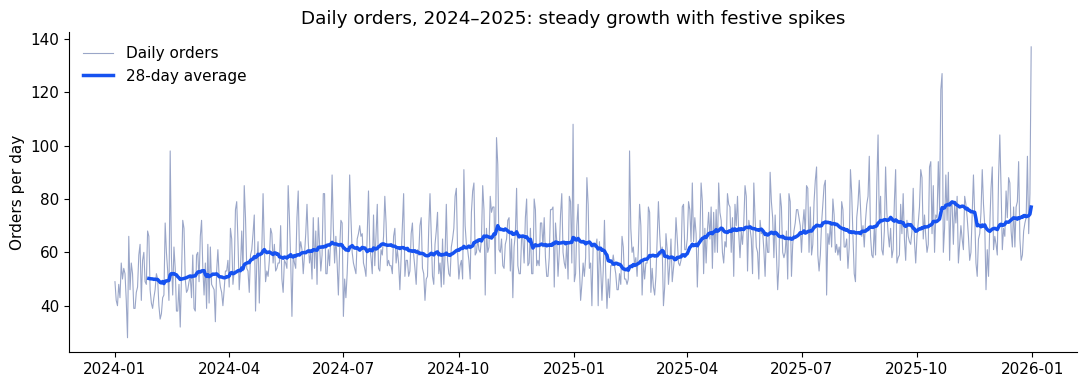

Average orders per day: 2024 = 59, 2025 = 67 (+13.7%)


In [3]:
fig, ax = plt.subplots()
ax.plot(daily.index, daily.orders, color=GREY, lw=0.8, label="Daily orders")
ax.plot(daily.index, daily.orders.rolling(28).mean(), color=BLUE, lw=2.5, label="28-day average")
ax.set_title("Daily orders, 2024–2025: steady growth with festive spikes")
ax.set_ylabel("Orders per day"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("images/1_daily_orders.png", dpi=150); plt.show()

growth = daily.loc["2025"].orders.mean() / daily.loc["2024"].orders.mean() - 1
print(f"Average orders per day: 2024 = {daily.loc['2024'].orders.mean():.0f}, 2025 = {daily.loc['2025'].orders.mean():.0f} (+{growth:.1%})")

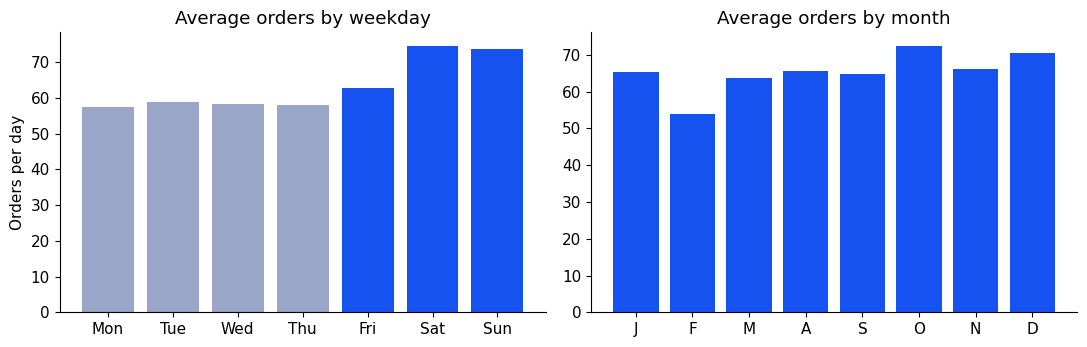

Weekends are 25% busier than weekdays.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
wd = daily.groupby(daily.index.dayofweek).orders.mean()
axes[0].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], wd, color=[GREY]*4 + [BLUE]*3)
axes[0].set_title("Average orders by weekday"); axes[0].set_ylabel("Orders per day")
mo = daily.groupby(daily.index.month).orders.mean()
axes[1].bar(["J","F","M","A","M","J","J","A","S","O","N","D"], mo, color=BLUE)
axes[1].set_title("Average orders by month")
plt.tight_layout(); plt.savefig("images/2_patterns.png", dpi=150); plt.show()
print(f"Weekends are {wd[5:].mean()/wd[:5].mean()-1:.0%} busier than weekdays.")

**What the charts show:** demand grows over time, weekends (and Fridays) are busier, April–May (IPL season) and festive days like Diwali and New Year's Eve spike, and early in the year is quieter. A good model needs all of these.

## 3. Create features the model can learn from

A model can't read a calendar, so we turn each date into numbers: how far into the timeline it is (trend), which weekday and month it is, and flags for monsoon, IPL season and festivals.

In [5]:
FESTIVALS = pd.to_datetime(["2024-02-14","2024-10-31","2024-11-01","2024-12-31",
                            "2025-02-14","2025-10-20","2025-10-21","2025-12-31",
                            "2026-02-14"])   # Valentine's Day, Diwali, New Year's Eve

def make_features(dates):
    X = pd.DataFrame(index=dates)
    X["trend"]    = (dates - pd.Timestamp("2024-01-01")).days
    X["weekend"]  = (dates.dayofweek >= 5).astype(int)
    X["friday"]   = (dates.dayofweek == 4).astype(int)
    X["ipl"]      = dates.month.isin([4, 5]).astype(int)
    X["monsoon"]  = dates.month.isin([6, 7, 8, 9]).astype(int)
    X["festival"] = dates.isin(FESTIVALS).astype(int)
    for m in range(2, 13):                       # month effects (January is the baseline)
        X[f"month_{m}"] = (dates.month == m).astype(int)
    for d in range(1, 7):                        # weekday effects (Monday is the baseline)
        X[f"dow_{d}"] = (dates.dayofweek == d).astype(int)
    return X

X_all, y_all = make_features(daily.index), daily.orders
X_all.head(3)

,trend,weekend,friday,ipl,monsoon,festival,month_2,month_3,month_4,month_5,...,month_9,month_10,month_11,month_12,dow_1,dow_2,dow_3,dow_4,dow_5,dow_6
OrderDateTime,,,,,,,,,,,,,,,,,,,,,
2024-01-01,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2024-01-02,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2024-01-03,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0


## 4. Test the methods fairly

We hide the last two months (**Nov–Dec 2025**), train on everything before, and check how close each method gets. This mimics real forecasting, where the future is unknown.

We compare:
- **Seasonal naive:** "the same as the same weekday last week". A simple baseline every model must beat.
- **Linear regression:** adds up the effects of trend, weekday, month and festivals.
- **Gradient boosting:** a machine-learning model that can learn more complex interactions.

**MAPE** (mean absolute percentage error) = the average % the forecast is off by. Lower is better.

In [6]:
split = "2025-11-01"
train, test = daily.loc[:"2025-10-31"], daily.loc[split:]
X_train, X_test = X_all.loc[train.index], X_all.loc[test.index]

preds = {}
preds["Seasonal naive"] = daily.orders.shift(7).loc[test.index]

lr = LinearRegression().fit(X_train, train.orders)
preds["Linear regression"] = pd.Series(lr.predict(X_test), index=test.index)

gb = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
gb.fit(X_train, train.orders)
preds["Gradient boosting"] = pd.Series(gb.predict(X_test), index=test.index)

scores = pd.DataFrame({name: {"MAE (orders/day)": mean_absolute_error(test.orders, p),
                              "MAPE": mean_absolute_percentage_error(test.orders, p)}
                       for name, p in preds.items()}).T.sort_values("MAPE")
scores.style.format({"MAE (orders/day)": "{:.1f}", "MAPE": "{:.1%}"})

,MAE (orders/day),MAPE
Linear regression,6.5,9.1%
Gradient boosting,7.3,9.6%
Seasonal naive,10.0,13.5%


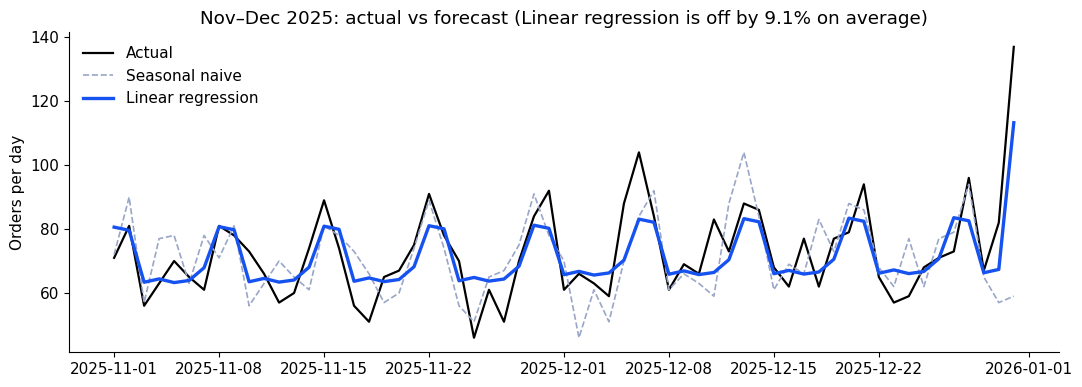

In [7]:
best = scores.index[0]
fig, ax = plt.subplots()
ax.plot(test.index, test.orders, color="black", lw=1.6, label="Actual")
ax.plot(test.index, preds["Seasonal naive"], color=GREY, lw=1.2, ls="--", label="Seasonal naive")
ax.plot(test.index, preds[best], color=BLUE, lw=2.4, label=best)
ax.set_title(f"Nov–Dec 2025: actual vs forecast ({best} is off by {scores.loc[best,'MAPE']:.1%} on average)")
ax.set_ylabel("Orders per day"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("images/3_test_period.png", dpi=150); plt.show()

## 5. Forecast January 2026

We retrain the best method on **all** the data and forecast the next 31 days. The shaded band shows the likely range, based on how far off the model typically was in testing.

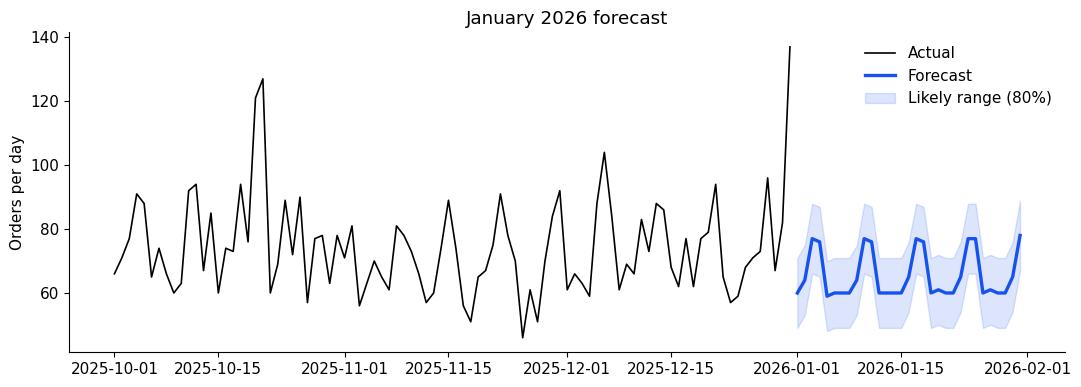

Forecast for January 2026: 2,035 orders (66 a day on average)


In [8]:
model = LinearRegression() if best == "Linear regression" else GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
model.fit(X_all, y_all)

future_dates = pd.date_range("2026-01-01", "2026-01-31", freq="D")
forecast = pd.Series(model.predict(make_features(future_dates)), index=future_dates).round()

err = (test.orders - preds[best]).std()           # typical error from the test period
low, high = forecast - 1.28 * err, forecast + 1.28 * err   # roughly an 80% range

fig, ax = plt.subplots()
ax.plot(daily.loc["2025-10-01":].index, daily.loc["2025-10-01":].orders, color="black", lw=1.2, label="Actual")
ax.plot(forecast.index, forecast, color=BLUE, lw=2.4, label="Forecast")
ax.fill_between(forecast.index, low, high, color=BLUE, alpha=0.15, label="Likely range (80%)")
ax.set_title("January 2026 forecast"); ax.set_ylabel("Orders per day"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("images/4_forecast_jan_2026.png", dpi=150); plt.show()
print(f"Forecast for January 2026: {forecast.sum():,.0f} orders ({forecast.mean():.0f} a day on average)")

## 6. From forecast to action: how many delivery partners?

Operations doesn't plan by day; it plans by the **busiest hour**. We use the historical share of orders that fall in the peak dinner hour, and assume one partner can complete about **2 orders an hour** (an assumption to check with the ops team).

In [9]:
peak_hour_share = orders.OrderDateTime.dt.hour.value_counts(normalize=True).max()
peak_hour = orders.OrderDateTime.dt.hour.value_counts().idxmax()
ORDERS_PER_PARTNER_PER_HOUR = 2      # assumption

plan = pd.DataFrame({"forecast_orders": forecast, "weekday": forecast.index.day_name()})
plan["peak_hour_orders"] = (plan.forecast_orders * peak_hour_share).round()
plan["partners_needed"] = np.ceil(high * peak_hour_share / ORDERS_PER_PARTNER_PER_HOUR).astype(int)   # plan for the high end

staffing = (plan.groupby("weekday")[["forecast_orders", "peak_hour_orders", "partners_needed"]].mean().round()
                .reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]))
print(f"Peak hour is {peak_hour}:00–{peak_hour+1}:00, with {peak_hour_share:.1%} of a day's orders.")
staffing.astype(int)

Peak hour is 20:00–21:00, with 11.5% of a day's orders.


,forecast_orders,peak_hour_orders,partners_needed
weekday,,,
Monday,60,7,5
Tuesday,60,7,5
Wednesday,60,7,5
Thursday,60,7,5
Friday,65,7,5
Saturday,77,9,6
Sunday,76,9,6


## Summary

- Orders grew about **14% year on year** (59 → 67 a day); weekends are **25% busier** than weekdays, and IPL months and festivals add predictable spikes.
- **Linear regression was the most accurate:** about **9% off** on two months of unseen data, against **13.5%** for the "same as last week" baseline, so it's roughly a third more accurate. The simpler model beat gradient boosting, a reminder that more complex isn't always better.
- **January 2026 forecast:** about **2,035 orders** (66 a day). Planning for the busy end of the range, the hub needs **5 partners** in the 8–9 pm peak on weekdays and **6** on weekends.

**Next steps:** add weather data (rain slows deliveries and changes demand), forecast by area and hour, and retrain monthly as new data arrives.